# Spatial analysis of the 2026 Alberta referendum, question 10
Joseph and Zarif. Adapted from a collaborator's Colab notebook; the script version is `scripts/06-spatial_analysis.py`.

**Read before citing.** Locations are *approximate riding centres*, not boundaries, so Moran's I and the neighbour weights are provisional until the Elections Alberta boundary file is used. There is no regression: the original notebook's covariates were randomly generated and were removed. Votes come from `data/02-analysis_data/ed_results_2026.csv`.

Maps use schematic (Voronoi) polygons, labelled as such. Run from the project root's `notebooks/` folder with the project virtual environment.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "scripts"))

import geopandas as gpd
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.gridspec import GridSpec
from shapely.geometry import MultiPoint, Point, Polygon
from shapely.ops import voronoi_diagram

from common import ANALYSIS, EXPECTED_2026, RAW

K_NEIGHBOURS = 5
N_PERMUTATIONS = 9999
SEED = 42
REGION_COLOURS = {"Edmonton": "#4575b4", "Calgary": "#74add1", "Central": "#fdae61",
                  "North": "#f46d43", "South": "#d73027"}
LISA_COLOURS = {"High-High": "#d73027", "Low-Low": "#4575b4",
                "High-Low": "#fdae61", "Low-High": "#abd9e9"}

## 1. Load question 10 and riding locations
Option 2 is the second choice on the ballot. The assertions tie the data to the published provincial totals.

In [2]:
results = pd.read_csv(ANALYSIS / "ed_results_2026.csv", dtype={"ed_code": str})
q10 = results[results["question_number"] == 10].copy()
q10["total"] = q10["choice_1_votes"] + q10["choice_2_votes"]
q10["option2_pct"] = 100 * q10["choice_2_votes"] / q10["total"]

centroids = pd.read_csv(RAW / "riding_centroids.csv", dtype={"ed_code": str})
df = q10.merge(centroids[["ed_code", "region", "lat", "lon"]], on="ed_code", how="left")

assert len(df) == 87 and df["lat"].notna().all()
assert df["choice_1_votes"].sum() == EXPECTED_2026[10]["choice_1"]
assert df["choice_2_votes"].sum() == EXPECTED_2026[10]["choice_2"]

y = df["option2_pct"].to_numpy()
print(f"Option 2 share, provincial: {100 * df['choice_2_votes'].sum() / df['total'].sum():.2f}%")
print(f"Divisions above 50%: {(y > 50).sum()}")
df.loc[y > 50, ["ed_name", "option2_pct"]]

Option 2 share, provincial: 25.05%
Divisions above 50%: 2


,ed_name,option2_pct
54,CENTRAL PEACE-NOTLEY,50.459921
79,RIMBEY-ROCKY MOUNTAIN HOUSE-SUNDRE,50.937487


## 2. Schematic riding map
**These are not real riding boundaries.** Each polygon is the Voronoi cell around an approximate riding centre, clipped to a hand-drawn provincial outline, so shapes and areas are indicative only. Replace with the Elections Alberta boundary file when available.

In [3]:
ab_poly = Polygon([(-120.0, 60.0), (-110.0, 60.0), (-110.0, 49.0), (-114.05, 49.0),
                   (-114.7, 49.3), (-115.3, 50.0), (-116.0, 50.8), (-116.9, 51.8),
                   (-117.8, 52.7), (-118.8, 53.5), (-120.0, 54.0)])
pts = [Point(xy) for xy in df[["lon", "lat"]].to_numpy()]
cells = list(voronoi_diagram(MultiPoint(pts), envelope=ab_poly.envelope.buffer(2.0)).geoms)

polys = []
for pt in pts:
    cell = next((c_ for c_ in cells if c_.contains(pt)), None) or min(cells, key=lambda c_: c_.distance(pt))
    clipped = cell.intersection(ab_poly)
    polys.append(clipped if not clipped.is_empty else pt.buffer(0.35).intersection(ab_poly))

gdf = gpd.GeoDataFrame(df, geometry=polys, crs="EPSG:4326")
print(len(gdf), "schematic polygons")

87 schematic polygons


## 3. Choropleth with Calgary and Edmonton insets

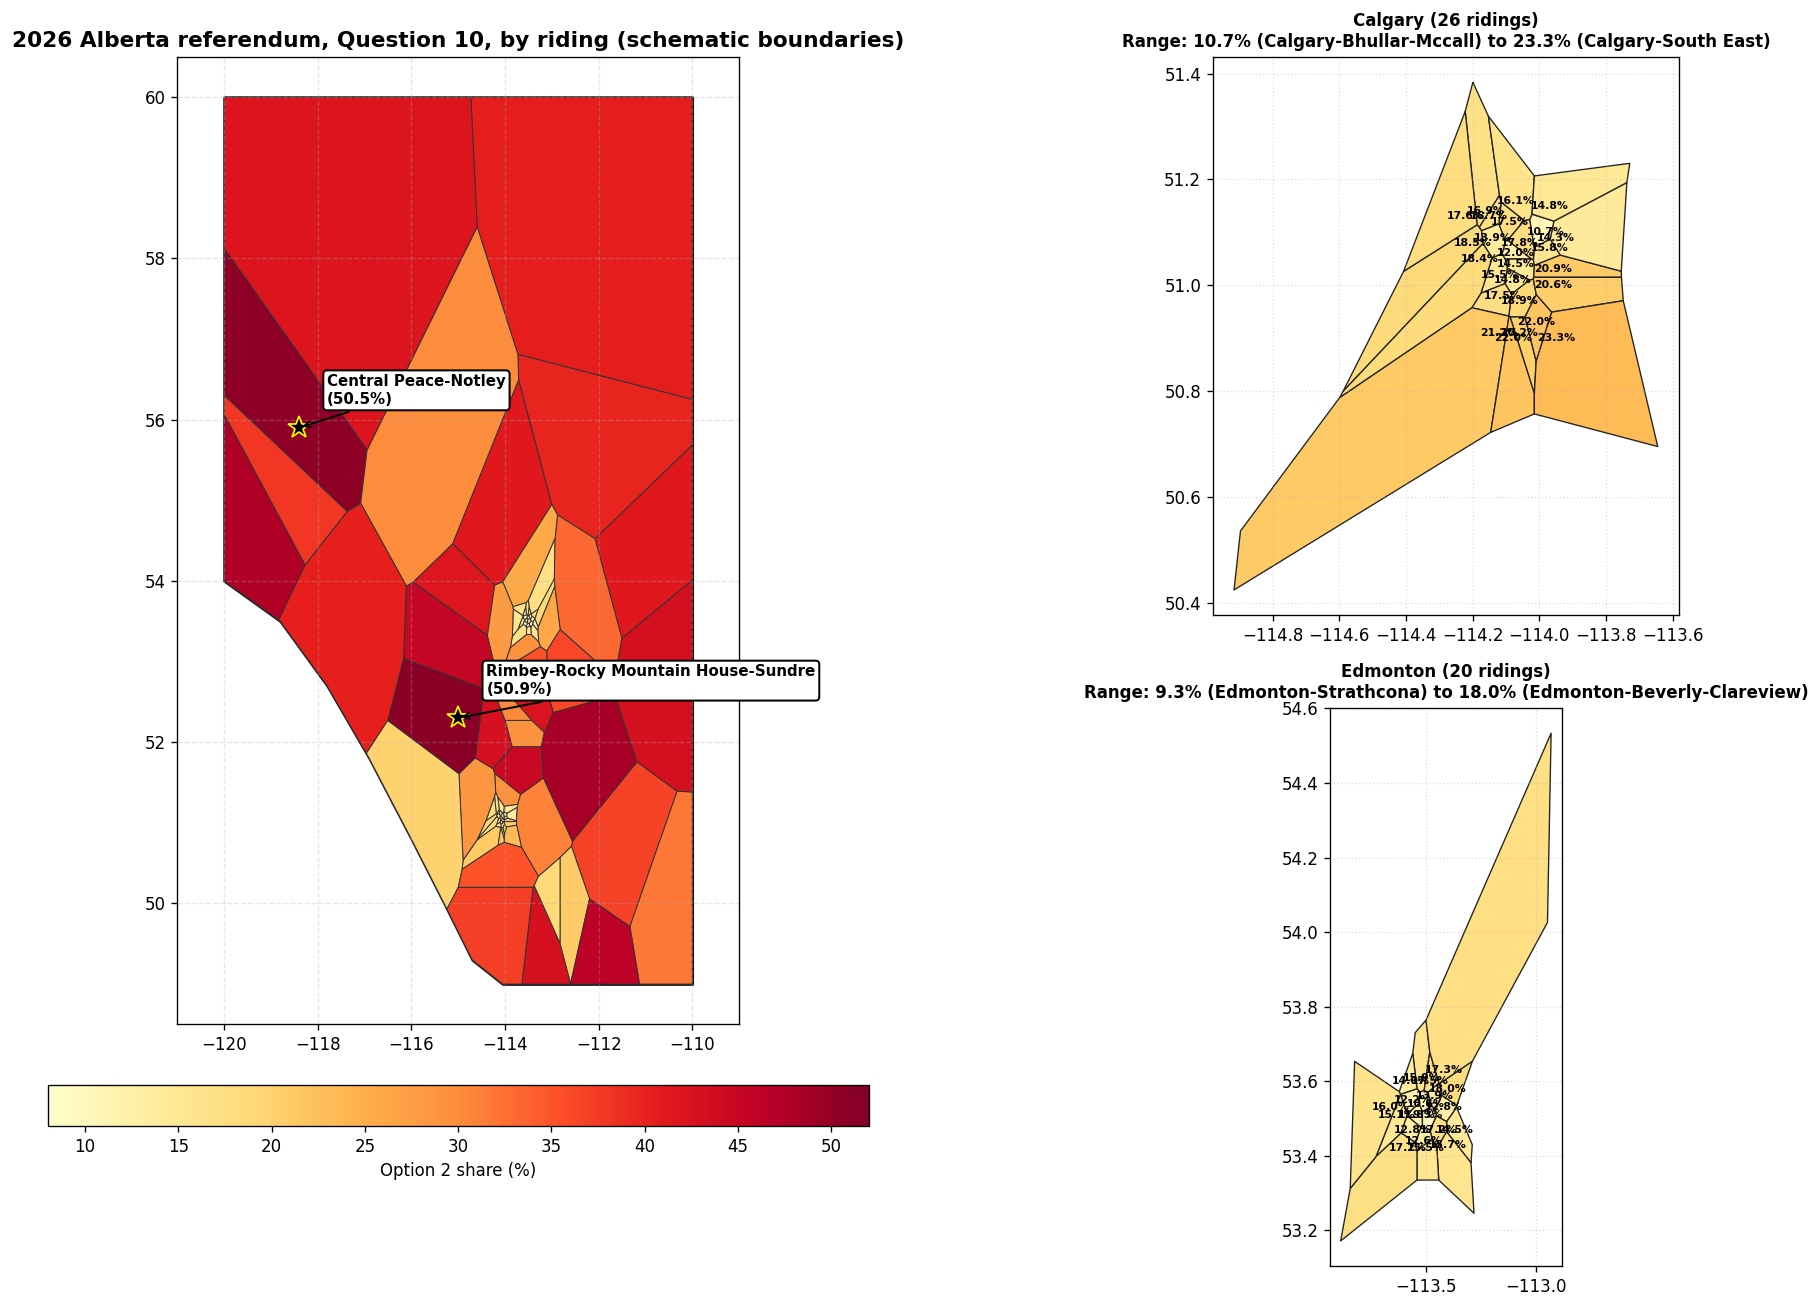

In [4]:
VMIN, VMAX = 8.0, 52.0
LABEL = "Option 2 share (%)"

fig = plt.figure(figsize=(18, 11), dpi=120)
gs = GridSpec(2, 2, width_ratios=[1.25, 1.0], height_ratios=[1.0, 1.0], figure=fig)
ax_main, ax_cal, ax_edm = (fig.add_subplot(gs[:, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, 1]))

gpd.GeoSeries([ab_poly]).plot(ax=ax_main, facecolor="#f5f5f5", edgecolor="#111111", linewidth=1.5)
gdf.plot(column="option2_pct", cmap="YlOrRd", vmin=VMIN, vmax=VMAX, linewidth=0.6,
         edgecolor="#333333", legend=True, ax=ax_main,
         legend_kwds={"label": LABEL, "orientation": "horizontal", "shrink": 0.65, "pad": 0.05})

for _, r in gdf[gdf["option2_pct"] > 50].iterrows():
    ax_main.plot(r["lon"], r["lat"], marker="*", markersize=14, color="black", markeredgecolor="yellow")
    ax_main.annotate(f"{r['ed_name'].title()}\n({r['option2_pct']:.1f}%)", xy=(r["lon"], r["lat"]),
                     xytext=(r["lon"] + 0.6, r["lat"] + 0.3), fontsize=9, fontweight="bold",
                     bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="black", lw=1.2),
                     arrowprops=dict(arrowstyle="->", color="black", lw=1.2))
ax_main.set_title("2026 Alberta referendum, Question 10, by riding (schematic boundaries)", fontsize=13, fontweight="bold")
ax_main.set_xlim(-121.0, -109.0); ax_main.set_ylim(48.5, 60.5)
ax_main.grid(True, linestyle="--", alpha=0.3)

for ax, region in ((ax_cal, "Calgary"), (ax_edm, "Edmonton")):
    sub = gdf[gdf["region"] == region]
    sub.plot(column="option2_pct", cmap="YlOrRd", vmin=VMIN, vmax=VMAX, linewidth=0.8, edgecolor="#222222", ax=ax)
    for _, r in sub.iterrows():
        ax.text(r["lon"], r["lat"], f"{r['option2_pct']:.1f}%", fontsize=6.5, ha="center", va="center", fontweight="bold")
    lo, hi = sub.loc[sub["option2_pct"].idxmin()], sub.loc[sub["option2_pct"].idxmax()]
    ax.set_title(f"{region} ({len(sub)} ridings)\nRange: {lo['option2_pct']:.1f}% ({lo['ed_name'].title()}) to {hi['option2_pct']:.1f}% ({hi['ed_name'].title()})",
                 fontsize=10, fontweight="bold")
    ax.grid(True, linestyle=":", alpha=0.4)
plt.tight_layout(); plt.show()

## 4. Spatial weights and Global Moran's I
Row-standardised k-nearest-neighbour weights, with longitude scaled by cos(latitude). The p-value comes from permuting the values across divisions.

In [5]:
def knn_weights(coords, k):
    scaled = coords.copy()
    scaled[:, 0] *= np.cos(np.radians(coords[:, 1].mean()))
    d = np.linalg.norm(scaled[:, None, :] - scaled[None, :, :], axis=2)
    np.fill_diagonal(d, np.inf)
    w = np.zeros_like(d)
    for i, cols in enumerate(np.argsort(d, axis=1)[:, :k]):
        w[i, cols] = 1.0
    return w / w.sum(axis=1, keepdims=True)

def morans_i(values, w):
    dev = values - values.mean()
    return (len(values) / w.sum()) * (dev @ w @ dev) / (dev @ dev)

coords = df[["lon", "lat"]].to_numpy()
W = knn_weights(coords, K_NEIGHBOURS)

rng = np.random.default_rng(SEED)
i_obs = morans_i(y, W)
i_perm = np.array([morans_i(rng.permutation(y), W) for _ in range(N_PERMUTATIONS)])
p_value = (1 + np.sum(i_perm >= i_obs)) / (N_PERMUTATIONS + 1)
print(f"Global Moran's I (k={K_NEIGHBOURS}): {i_obs:.4f}, pseudo p = {p_value:.4f}")
pd.Series({k: morans_i(y, knn_weights(coords, k)) for k in (3, 5, 7, 10)}, name="Moran's I").rename_axis("k").round(4).to_frame()

Global Moran's I (k=5): 0.6496, pseudo p = 0.0001


,Moran's I
k,
3,0.6797
5,0.6496
7,0.6013
10,0.4888


## 5. LISA clusters
Descriptive only: no local significance test, so a quadrant label is not evidence of a real cluster.

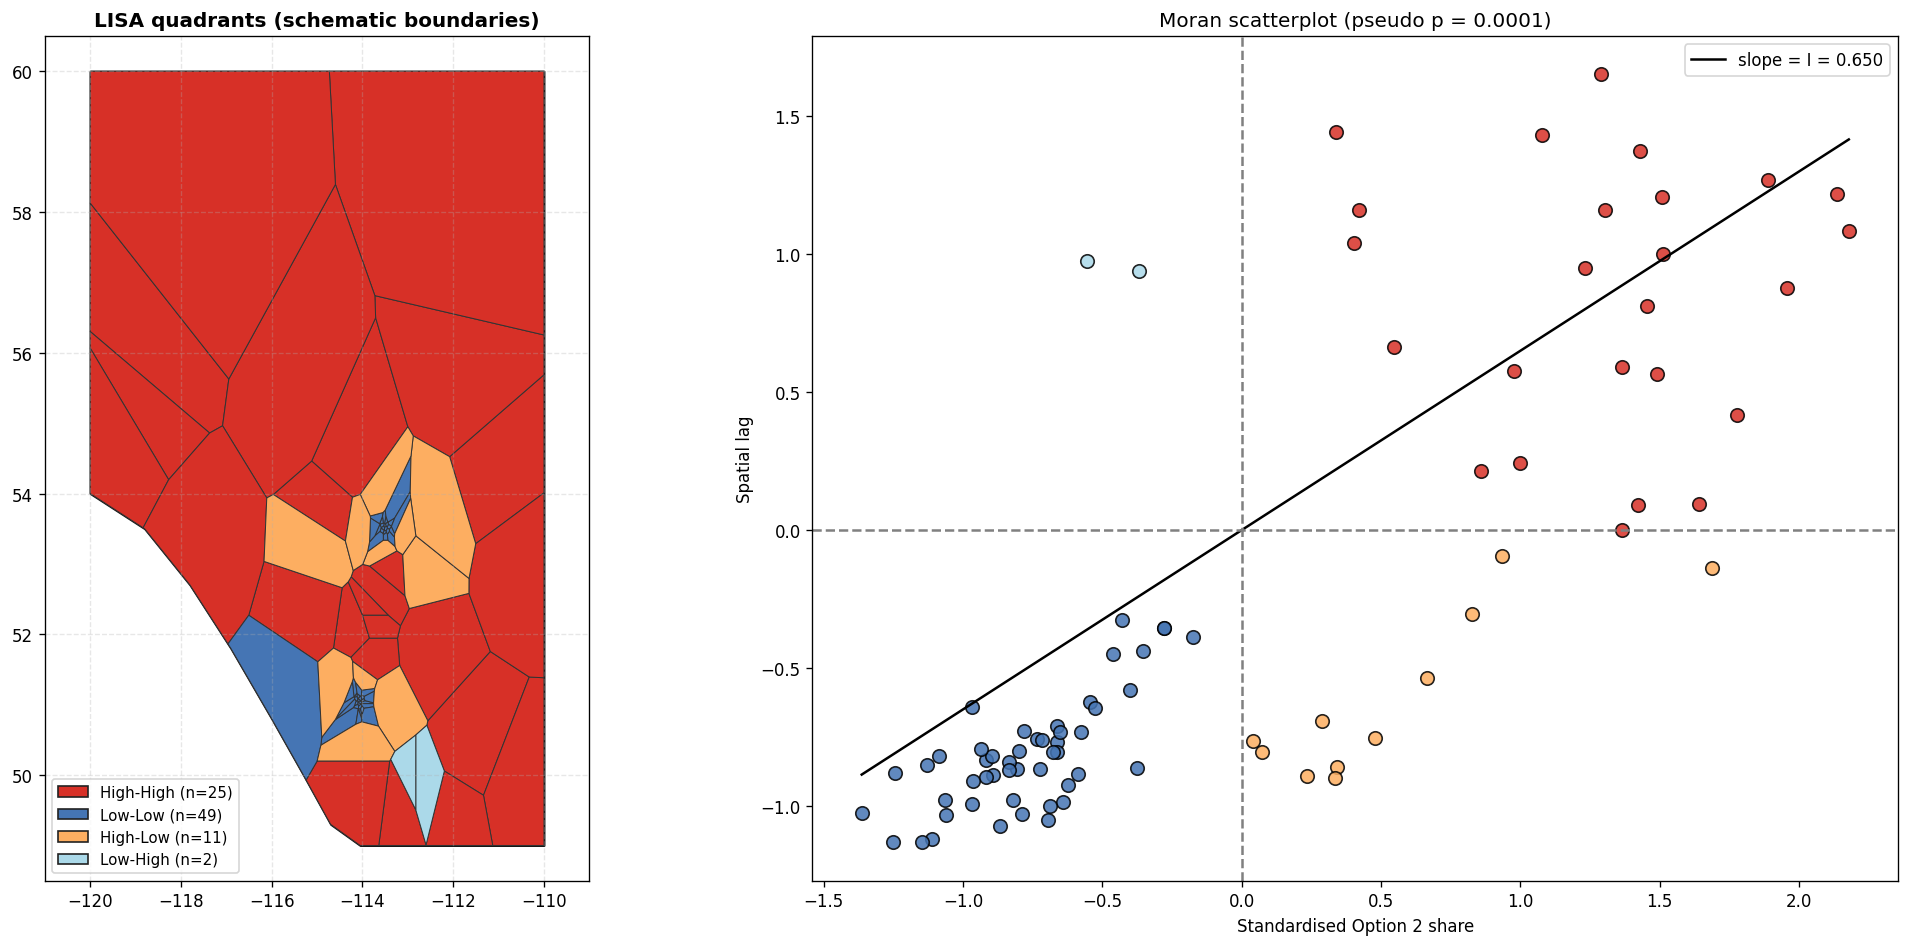

lisa
Low-Low      49
High-High    25
High-Low     11
Low-High      2
Name: count, dtype: int64

In [6]:
z = (y - y.mean()) / y.std()
lag = W @ z
df["z"], df["lag"] = z, lag
df["lisa"] = np.select(
    [(z > 0) & (lag > 0), (z < 0) & (lag < 0), (z > 0) & (lag < 0)],
    ["High-High", "Low-Low", "High-Low"], default="Low-High")

fig, (ax_map, ax_sc) = plt.subplots(1, 2, figsize=(18, 8), dpi=120)
gdf["lisa"] = df["lisa"].to_numpy()
gpd.GeoSeries([ab_poly]).plot(ax=ax_map, facecolor="#f5f5f5", edgecolor="#111111", linewidth=1.2)
patches = []
for name, colour in LISA_COLOURS.items():
    sub = gdf[gdf["lisa"] == name]
    if len(sub):
        sub.plot(color=colour, edgecolor="#333333", linewidth=0.6, ax=ax_map)
    ax_sc.scatter(df.loc[df["lisa"] == name, "z"], df.loc[df["lisa"] == name, "lag"], c=colour, s=65, edgecolor="black", alpha=0.85)
    patches.append(mpatches.Patch(facecolor=colour, edgecolor="#222222", label=f"{name} (n={len(sub)})"))
ax_map.legend(handles=patches, loc="lower left", fontsize=9)
ax_map.set_title("LISA quadrants (schematic boundaries)", fontsize=12, fontweight="bold")
ax_map.set_xlim(-121.0, -109.0); ax_map.set_ylim(48.5, 60.5)
ax_map.grid(True, linestyle="--", alpha=0.3)
xs = np.linspace(z.min(), z.max(), 20)
ax_sc.plot(xs, i_obs * xs, color="black", label=f"slope = I = {i_obs:.3f}")
ax_sc.axhline(0, color="grey", linestyle="--"); ax_sc.axvline(0, color="grey", linestyle="--")
ax_sc.set_xlabel("Standardised Option 2 share"); ax_sc.set_ylabel("Spatial lag")
ax_sc.set_title(f"Moran scatterplot (pseudo p = {p_value:.4f})")
ax_sc.legend()
plt.tight_layout(); plt.show()
df["lisa"].value_counts()

## 6. Rankings and regional comparison

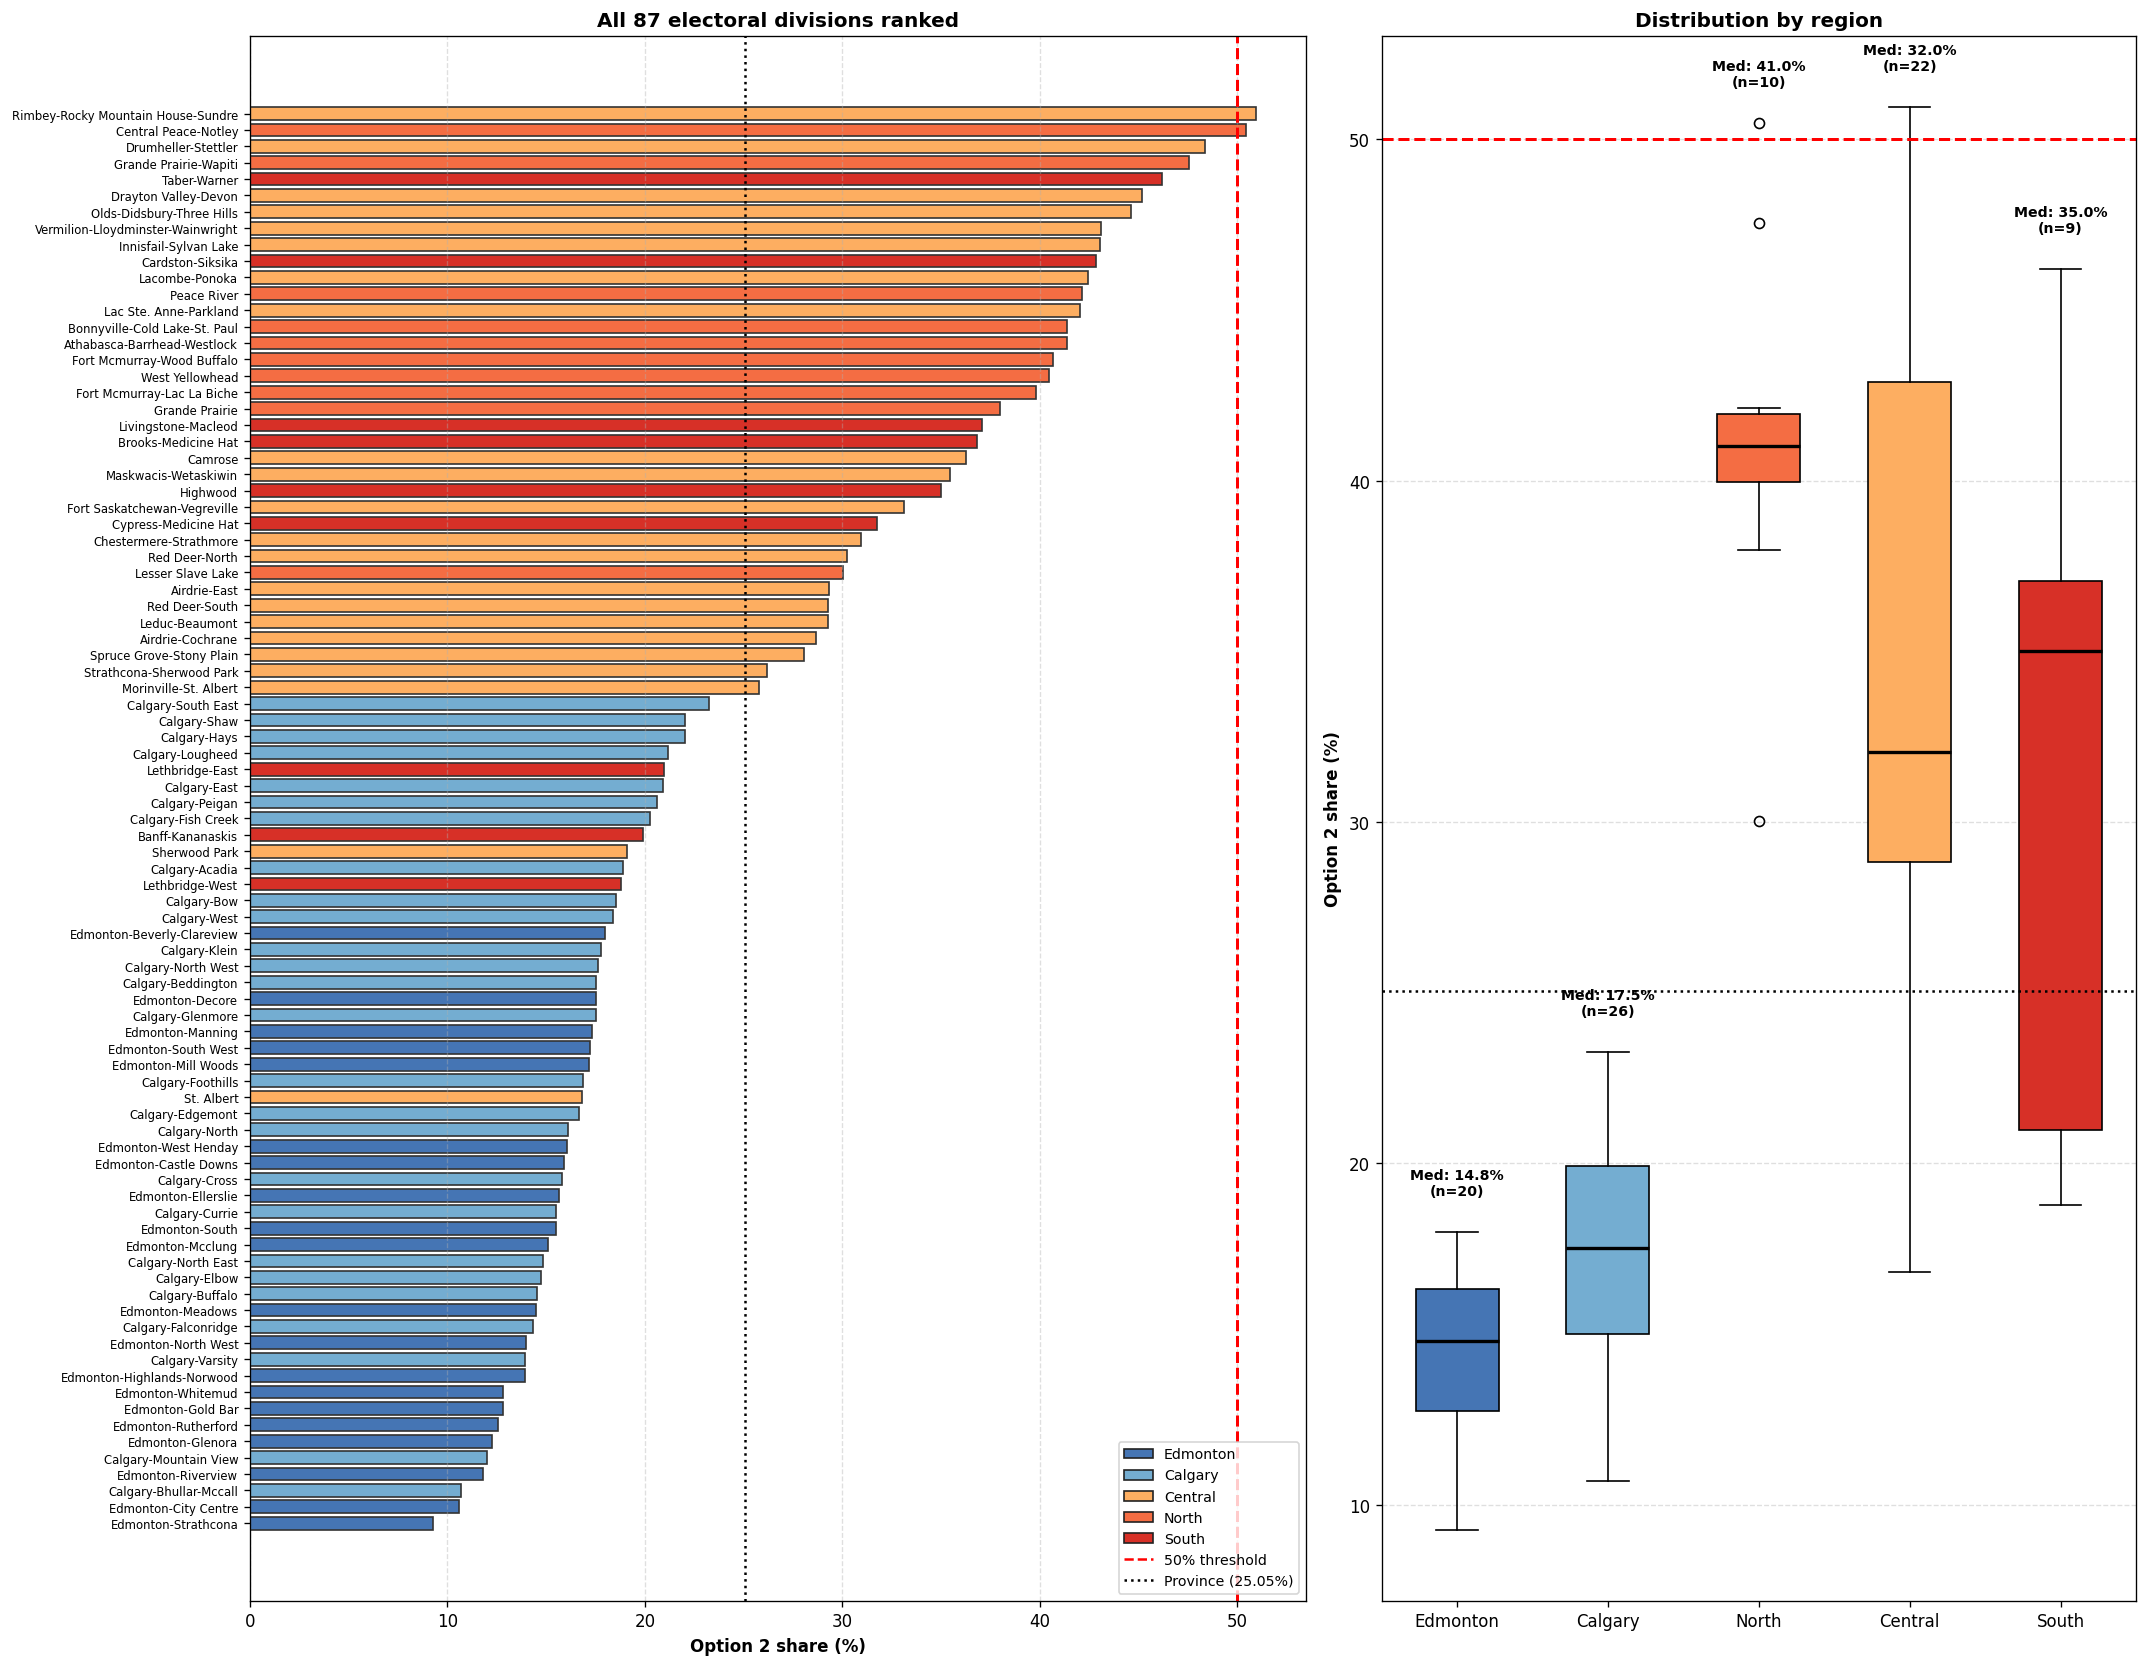

,n,median,mean,min,max
region,,,,,
Calgary,26,17.51,17.41,10.68,23.27
Central,22,32.04,34.47,16.81,50.94
Edmonton,20,14.80,14.50,9.28,17.99
North,10,41.01,41.18,30.04,50.46
South,9,35.02,32.15,18.78,46.20


In [7]:
prov = 100 * df["choice_2_votes"].sum() / df["total"].sum()
order = ["Edmonton", "Calgary", "North", "Central", "South"]
ranked = df.sort_values("option2_pct")

fig, (ax_bar, ax_box) = plt.subplots(1, 2, figsize=(18, 14), dpi=120, gridspec_kw={"width_ratios": [1.4, 1.0]})
ax_bar.barh(np.arange(len(ranked)), ranked["option2_pct"], color=[REGION_COLOURS[r] for r in ranked["region"]],
            edgecolor="#333333", height=0.78)
ax_bar.axvline(50, color="red", linestyle="--", linewidth=1.8)
ax_bar.axvline(prov, color="black", linestyle=":", linewidth=1.5)
ax_bar.set_yticks(np.arange(len(ranked))); ax_bar.set_yticklabels(ranked["ed_name"].str.title(), fontsize=7)
ax_bar.set_xlabel("Option 2 share (%)", fontweight="bold")
ax_bar.set_title("All 87 electoral divisions ranked", fontsize=12, fontweight="bold")
handles = [mpatches.Patch(facecolor=c_, edgecolor="#222222", label=r) for r, c_ in REGION_COLOURS.items()]
handles += [plt.Line2D([0], [0], color="red", linestyle="--", label="50% threshold"),
            plt.Line2D([0], [0], color="black", linestyle=":", label=f"Province ({prov:.2f}%)")]
ax_bar.legend(handles=handles, loc="lower right", fontsize=8.5)
ax_bar.grid(True, axis="x", linestyle="--", alpha=0.4)

bp = ax_box.boxplot([df.loc[df["region"] == r, "option2_pct"] for r in order], tick_labels=order, patch_artist=True, widths=0.55)
for patch, r in zip(bp["boxes"], order):
    patch.set_facecolor(REGION_COLOURS[r])
for med in bp["medians"]:
    med.set(color="black", linewidth=2)
ax_box.axhline(50, color="red", linestyle="--", linewidth=1.8)
ax_box.axhline(prov, color="black", linestyle=":", linewidth=1.5)
for i, r in enumerate(order, start=1):
    sub = df.loc[df["region"] == r, "option2_pct"]
    ax_box.text(i, sub.max() + 1.0, f"Med: {sub.median():.1f}%\n(n={len(sub)})", ha="center", va="bottom", fontsize=8.5, fontweight="bold")
ax_box.set_ylabel("Option 2 share (%)", fontweight="bold")
ax_box.set_title("Distribution by region", fontsize=12, fontweight="bold")
ax_box.grid(True, axis="y", linestyle="--", alpha=0.4)
plt.tight_layout(); plt.show()

display(df.groupby("region")["option2_pct"].agg(n="count", median="median", mean="mean", min="min", max="max").round(2))

## Next steps
- Replace approximate centres with the Elections Alberta boundary file, then recompute weights (queen contiguity) and Moran's I.
- Add a local significance test for LISA.
- Add real covariates (for example Statistics Canada indicators, 2023 election results) before any spatial lag model.